       Measurements  Sample  RSSI_dBm
0     0dBm_messung1       1     -60.0
1     0dBm_messung1       2     -60.0
2     0dBm_messung1       3     -60.0
3     0dBm_messung1       4     -60.0
4     0dBm_messung1       5     -60.0
...             ...     ...       ...
4790  0dBm_messung5     959       NaN
4791  0dBm_messung5     960       NaN
4792  0dBm_messung5     961       NaN
4793  0dBm_messung5     962       NaN
4794  0dBm_messung5     963       NaN

[4795 rows x 3 columns]


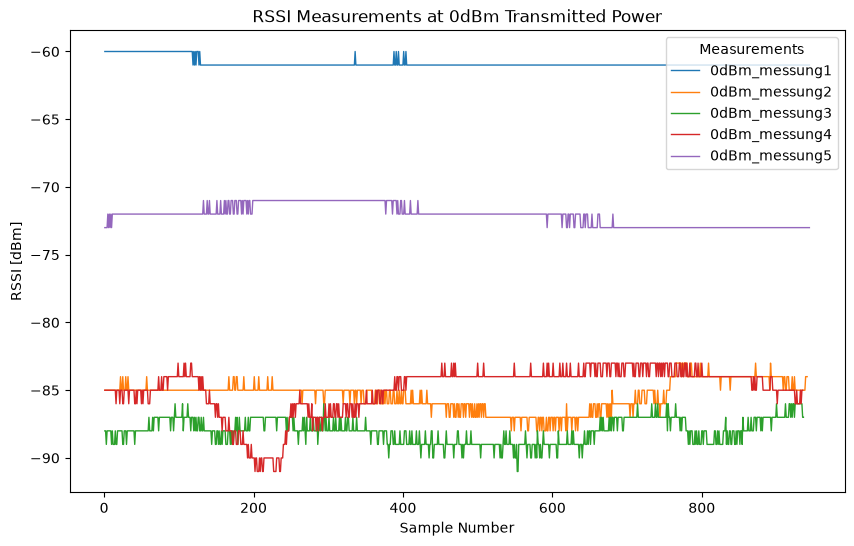

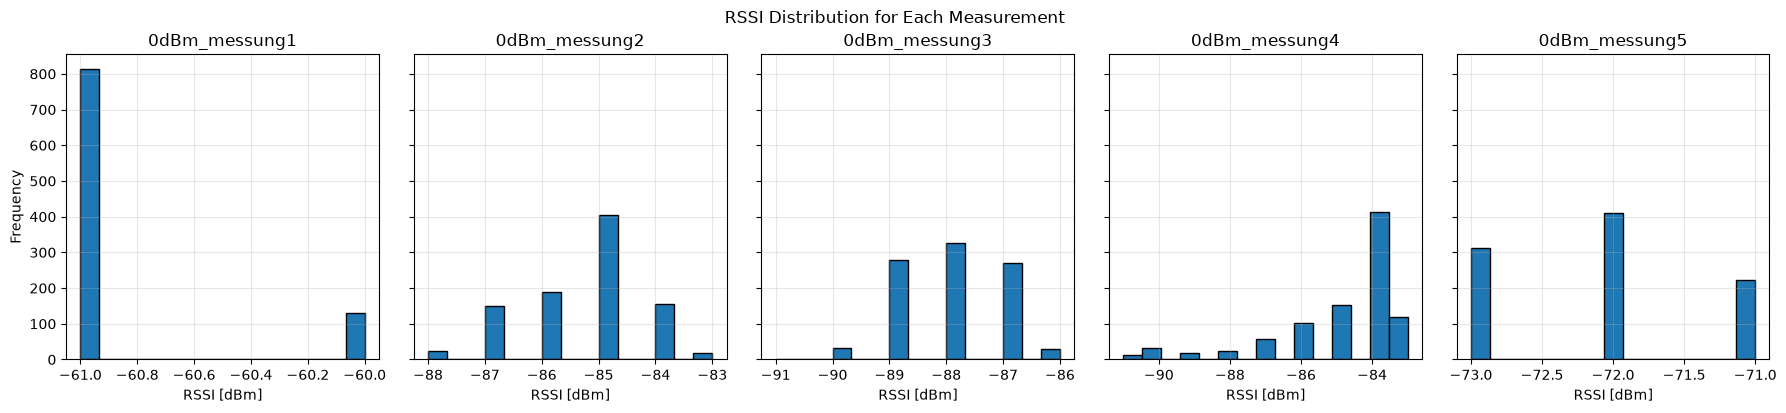

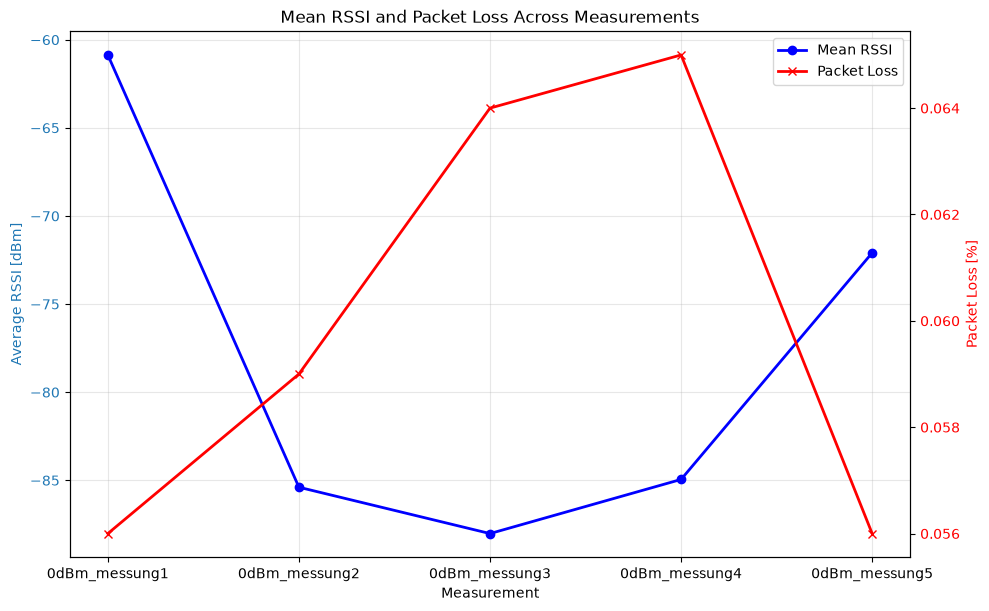

               sampels       mean  median       std   min   max   q25   q75  \
Measurements                                                                  
0dBm_messung1      944 -60.862288   -61.0  0.344780 -61.0 -60.0 -61.0 -61.0   
0dBm_messung2      941 -85.392136   -85.0  1.078958 -88.0 -83.0 -86.0 -85.0   
0dBm_messung3      936 -88.021368   -88.0  0.925903 -91.0 -86.0 -89.0 -87.0   
0dBm_messung4      935 -84.949733   -84.0  1.802519 -91.0 -83.0 -86.0 -84.0   
0dBm_messung5      944 -72.092161   -72.0  0.747553 -73.0 -71.0 -73.0 -72.0   

               packet_loss  range  coefficient_of_variation  
Measurements                                                 
0dBm_messung1        0.056    1.0                  0.005665  
0dBm_messung2        0.059    5.0                  0.012635  
0dBm_messung3        0.064    5.0                  0.010519  
0dBm_messung4        0.065    8.0                  0.021219  
0dBm_messung5        0.056    2.0                  0.010369  


In [ ]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
from pathlib import Path
import re

data_dir = Path("./Measurements")
image_dir = Path("../Reports/images")
files = sorted(data_dir.glob("0dBm_messung*.txt"))

def save_plot(fig, title):
    filename = re.sub(r"[^\w\s-]", "", title)
    filename = re.sub(r"[\s-]+", "_", filename).strip("_")
    fig.savefig(image_dir / f"{filename}.png", dpi=300, bbox_inches="tight")

measurements = [] 

for file in files:
    df = pd.read_csv(file, header=None, names=["raw"], dtype=str)

    df["RSSI_dBm"] = (
        df["raw"]
        .str.extract(r"RX-RSSI=(-?\d+(?:\.\d+)?)", expand=False)
        .astype(float)
    )

    df["Sample"] = np.arange(1, len(df) + 1)
    df["Measurements"] = file.stem 

    measurements.append(df[["Measurements", "Sample", "RSSI_dBm"]])

data = pd.concat(measurements, ignore_index=True)
print(data)

summary = data.groupby("Measurements")["RSSI_dBm"].agg(
    sampels="count", 
    mean="mean",
    median="median", 
    std="std", 
    min="min",
    max ="max",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
)
summary["packet_loss"] = 1 - (summary["sampels"] / 1000)

summary["range"] = summary["max"] - summary["min"]
summary["coefficient_of_variation"] = summary["std"] / summary["mean"].abs() 
summary.round(2) 

title = "0dBM RSSI Measurements at 0dBm Transmitted Power"

fig = plt.figure(figsize=(10, 6))
for name, group in data.groupby("Measurements"):
    plt.plot(
        group["Sample"],
        group["RSSI_dBm"],
        label=name,
        linewidth=1
    )

plt.title(title)
plt.xlabel("Sample Number")
plt.ylabel("RSSI [dBm]")
plt.legend(title="Measurements")
save_plot(fig, title)
plt.show()

title = "0dBM RSSI Distribution for Each Measurement"

fig, axes = plt.subplots(1, len(files), figsize=(18, 4), sharey=True)

for ax, (name, group) in zip(axes, data.groupby("Measurements")):
    ax.hist(group["RSSI_dBm"], bins=15, edgecolor="black")
    ax.set_title(name)
    ax.set_xlabel("RSSI [dBm]")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Frequency")
plt.tight_layout()
plt.suptitle(title, y=1.02)
save_plot(fig, title)
plt.show()

fig, ax1 = plt.subplots(figsize=(10, 6))

signal_strength = ax1.plot(
    summary.index,
    summary["mean"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Mean RSSI"
)

title = "0dBM Mean RSSI and Packet Loss Across Measurements"

ax1.set_xlabel("Measurement")
ax1.set_ylabel("Average RSSI [dBm]", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(True, alpha=0.3)


ax2 = ax1.twinx()
packet_loss = ax2.plot(
    summary.index,
    summary["packet_loss"],
    color="red",
    marker="x",
    linewidth=2,
    label="Packet Loss"
)

ax2.set_ylabel("Packet Loss [%]", color="red")
ax2.tick_params(axis="y", labelcolor="red")

lines = signal_strength + packet_loss 
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best")
plt.tight_layout()
plt.title(title)
save_plot(fig, title)
plt.show()

print(summary)